In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf


from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import seaborn as sns

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [2]:
VOCAB_SIZE = 10000
MAX_LEN = 250

(X_train_raw, y_train), (X_test_raw, y_test) = imdb.load_data(num_words=VOCAB_SIZE)

word_index = imdb.get_word_index()
index_word = {index + 3: word for word, index in word_index.items()}
index_word[0] = "<PAD>"
index_word[1] = "<START>"
index_word[2] = "<UNK>"
index_word[3] = "<UNUSED>"

def decode_review(sequence):
    return " ".join(index_word.get(index, "<UNK>") for index in sequence if index > 3)

train_texts = [decode_review(seq) for seq in X_train_raw]
test_texts = [decode_review(seq) for seq in X_test_raw]

print("Training samples:", len(train_texts))
print("Testing samples:", len(test_texts))
print("Vocabulary size:", VOCAB_SIZE)
print("Sample review:", train_texts[0][:500])
print("Sample label:", "Positive" if y_train[0] == 1 else "Negative")

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 25000
Testing samples: 25000
Vocabulary size: 10000
Sample review: this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to 
Sample label: Positive


In [3]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

clean_train_texts = [clean_text(text) for text in train_texts]
clean_test_texts = [clean_text(text) for text in test_texts]

print(clean_train_texts[0][:500])

this film was just brilliant casting location scenery story direction everyone s really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to 


In [4]:
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
import nltk

nltk.download("stopwords", quiet=True)
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

def preprocess_text(text):
    tokens = text.split()
    tokens = [token for token in tokens if token not in stop_words]
    tokens = [stemmer.stem(token) for token in tokens]
    return " ".join(tokens)

processed_train_texts = [preprocess_text(text) for text in clean_train_texts]
processed_test_texts = [preprocess_text(text) for text in clean_test_texts]

print(processed_train_texts[0][:500])

film brilliant cast locat sceneri stori direct everyon realli suit part play could imagin robert amaz actor director father came scottish island love fact real connect film witti remark throughout film great brilliant much bought film soon releas would recommend everyon watch fli fish amaz realli cri end sad know say cri film must good definit also two littl boy play norman paul brilliant children often left list think star play grown big profil whole film children amaz prais done think whole st


In [5]:
count_vectorizer = CountVectorizer(max_features=10000)
X_train_bow = count_vectorizer.fit_transform(processed_train_texts)
X_test_bow = count_vectorizer.transform(processed_test_texts)

tfidf_vectorizer = TfidfVectorizer(max_features=10000)
X_train_tfidf = tfidf_vectorizer.fit_transform(processed_train_texts)
X_test_tfidf = tfidf_vectorizer.transform(processed_test_texts)

print("BoW training shape:", X_train_bow.shape)
print("TF-IDF training shape:", X_train_tfidf.shape)

BoW training shape: (25000, 6502)
TF-IDF training shape: (25000, 6502)


In [6]:
X_train = pad_sequences(X_train_raw, maxlen=MAX_LEN, padding="post", truncating="post")
X_test = pad_sequences(X_test_raw, maxlen=MAX_LEN, padding="post", truncating="post")

X_train.shape, X_test.shape

((25000, 250), (25000, 250))

In [7]:
model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=128, input_length=MAX_LEN),
    LSTM(64, dropout=0.2, recurrent_dropout=0.0),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [8]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    np.array(y_train),
    epochs=8,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 93s 567ms/step - accuracy: 0.5048 - loss: 0.6931 - val_accuracy: 0.5410 - val_loss: 0.6791
Epoch 2/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 143s 577ms/step - accuracy: 0.5529 - loss: 0.6707 - val_accuracy: 0.5594 - val_loss: 0.6744
Epoch 3/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 105s 670ms/step - accuracy: 0.6028 - loss: 0.6103 - val_accuracy: 0.6094 - val_loss: 0.6464
Epoch 4/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 132s 606ms/step - accuracy: 0.6295 - loss: 0.5634 - val_accuracy: 0.5910 - val_loss: 0.6957
Epoch 5/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 88s 564ms/step - accuracy: 0.6335 - loss: 0.5395 - val_accuracy: 0.5864 - val_loss: 0.7221


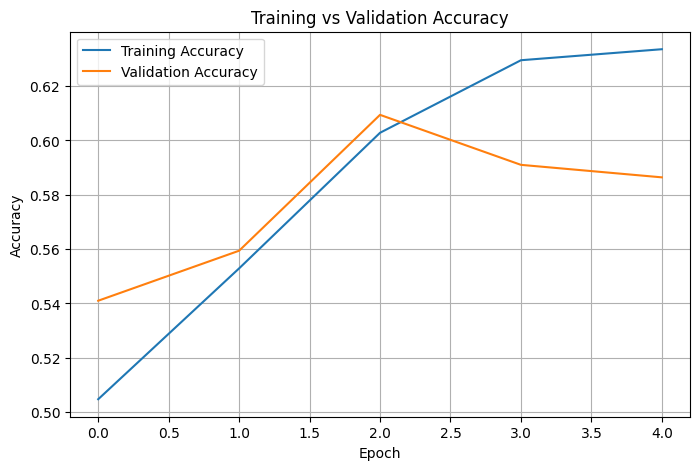

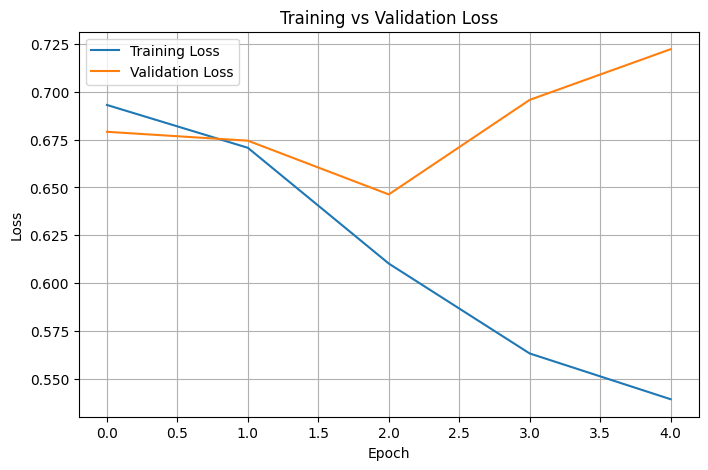

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Score": [accuracy, precision, recall, f1]
})

display(metrics_df)
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

,Metric,Score
0,Accuracy,0.587560
1,Precision,0.798799
2,Recall,0.234080
3,F1 Score,0.362061


              precision    recall  f1-score   support

    Negative       0.55      0.94      0.70     12500
    Positive       0.80      0.23      0.36     12500

    accuracy                           0.59     25000
   macro avg       0.68      0.59      0.53     25000
weighted avg       0.68      0.59      0.53     25000



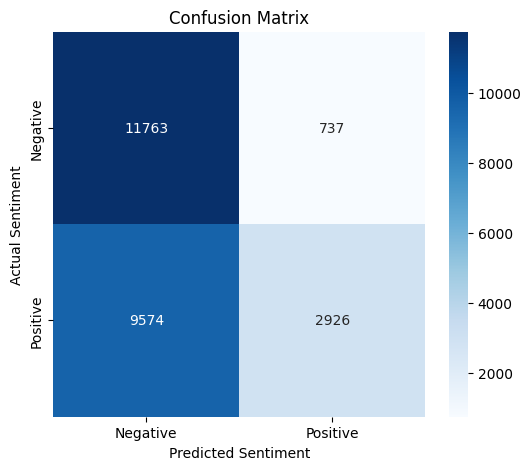

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Confusion Matrix")
plt.show()

,Actual Sentiment,Predicted Sentiment
0,Negative,Negative
1,Positive,Positive
2,Positive,Positive
3,Negative,Negative
4,Positive,Negative
5,Positive,Negative
6,Positive,Positive
7,Negative,Negative
8,Negative,Negative
9,Positive,Negative


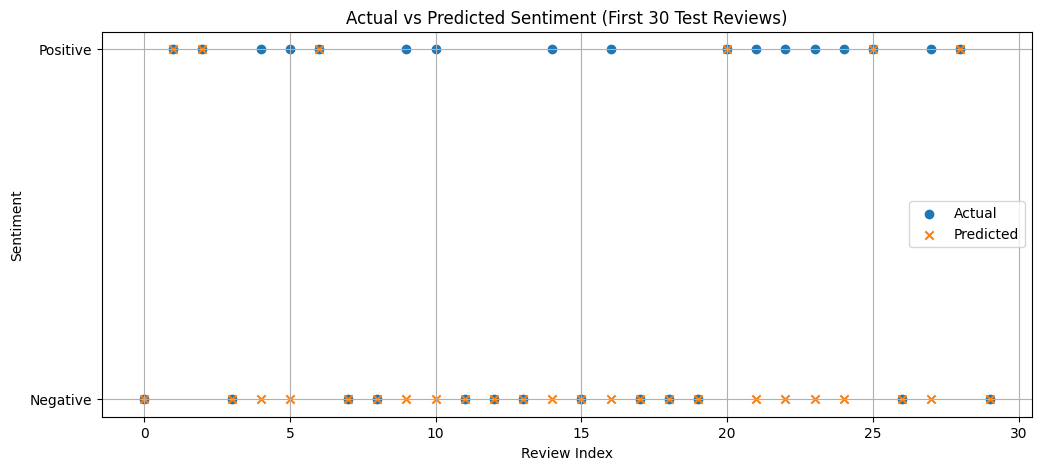

In [12]:
comparison_df = pd.DataFrame({
    "Actual": y_test[:30],
    "Predicted": y_pred[:30]
})

comparison_df["Actual Sentiment"] = comparison_df["Actual"].map({0: "Negative", 1: "Positive"})
comparison_df["Predicted Sentiment"] = comparison_df["Predicted"].map({0: "Negative", 1: "Positive"})

display(comparison_df[["Actual Sentiment", "Predicted Sentiment"]])

plt.figure(figsize=(12, 5))
positions = np.arange(len(comparison_df))
plt.scatter(positions, comparison_df["Actual"], label="Actual", marker="o")
plt.scatter(positions, comparison_df["Predicted"], label="Predicted", marker="x")
plt.yticks([0, 1], ["Negative", "Positive"])
plt.xlabel("Review Index")
plt.ylabel("Sentiment")
plt.title("Actual vs Predicted Sentiment (First 30 Test Reviews)")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
def predict_sentiment(review):
    cleaned = clean_text(review)
    sequence = []
    for token in cleaned.split():
        index = word_index.get(token)
        if index is None or index + 3 >= VOCAB_SIZE:
            sequence.append(2)
        else:
            sequence.append(index + 3)
    sequence = pad_sequences([sequence], maxlen=MAX_LEN, padding="post", truncating="post")
    probability = float(model.predict(sequence, verbose=0)[0][0])
    label = "Positive" if probability >= 0.5 else "Negative"
    return label, probability

sample_reviews = [
    "This movie was amazing, excellent, and entertaining. I loved every minute.",
    "The movie was boring, disappointing, and a complete waste of time.",
    "The acting was good but the story was not very interesting."
]

for review in sample_reviews:
    sentiment, probability = predict_sentiment(review)
    print("Review:", review)
    print("Prediction:", sentiment)
    print("Positive probability:", round(probability, 4))
    print()

Review: This movie was amazing, excellent, and entertaining. I loved every minute.
Prediction: Negative
Positive probability: 0.4975

Review: The movie was boring, disappointing, and a complete waste of time.
Prediction: Negative
Positive probability: 0.4975

Review: The acting was good but the story was not very interesting.
Prediction: Negative
Positive probability: 0.4975



In [14]:
model.save("imdb_lstm_sentiment_model.keras")
print("Model saved successfully.")

Model saved successfully.


In [15]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Test Loss:", round(float(test_loss), 4))
print("Test Accuracy:", round(float(test_accuracy), 4))

Test Loss: 0.6706
Test Accuracy: 0.5876


In [16]:
results = pd.DataFrame({
    "Model": ["LSTM with Embeddings"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1 Score": [f1]
})
display(results)

,Model,Accuracy,Precision,Recall,F1 Score
0,LSTM with Embeddings,0.58756,0.798799,0.23408,0.362061
